In [45]:
import physics_tools.coordinates as coords
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import uncertainties as unc
from pathlib import Path

def conv_angles(x, y, right=False):
    return coords.double_pendulum_angles(*coords.double_pendulum_conv(x, y), right=right)

In [46]:
#SCRIPT_DIR = Path(__file__).parent
DATA_DIR = "initial_positions.csv"
PLOT_DIR_FINAL = "final_plots"

In [47]:
g = 9.81
m_1 = 1
m_2 = 1
L_1 = 1
L_2 = 1

# potential energy
def pot_energy(theta_1, theta_2):
    V_1 = -m_1*g*L_1*np.cos(theta_1)
    V_2 = -m_2*g*(L_1*np.cos(theta_1) + L_2*np.cos(theta_2))
    return V_1 + V_2


In [ ]:
data = pd.read_csv(DATA_DIR, skiprows=1, names=["x", "y", "joint", "flip"])
#print(data)

X = data["x"]
Y = data["y"]
joint = data["joint"]
flip = data["flip"]

theta_1 = np.zeros_like(X)
theta_2 = np.zeros_like(Y)
for i,_ in enumerate(X):
    rad_1, rad_2 = conv_angles(X[i], Y[i])
    theta_1[i], theta_2[i] = rad_1 / (2 * np.pi) * 360, rad_2 / (2 * np.pi) * 360

right = joint
for i, j in enumerate(joint):
    if j == "down" and theta_2[i] < 0:
        right[i] = True

TypeError: unsupported operand type(s) for /: 'tuple' and 'float'

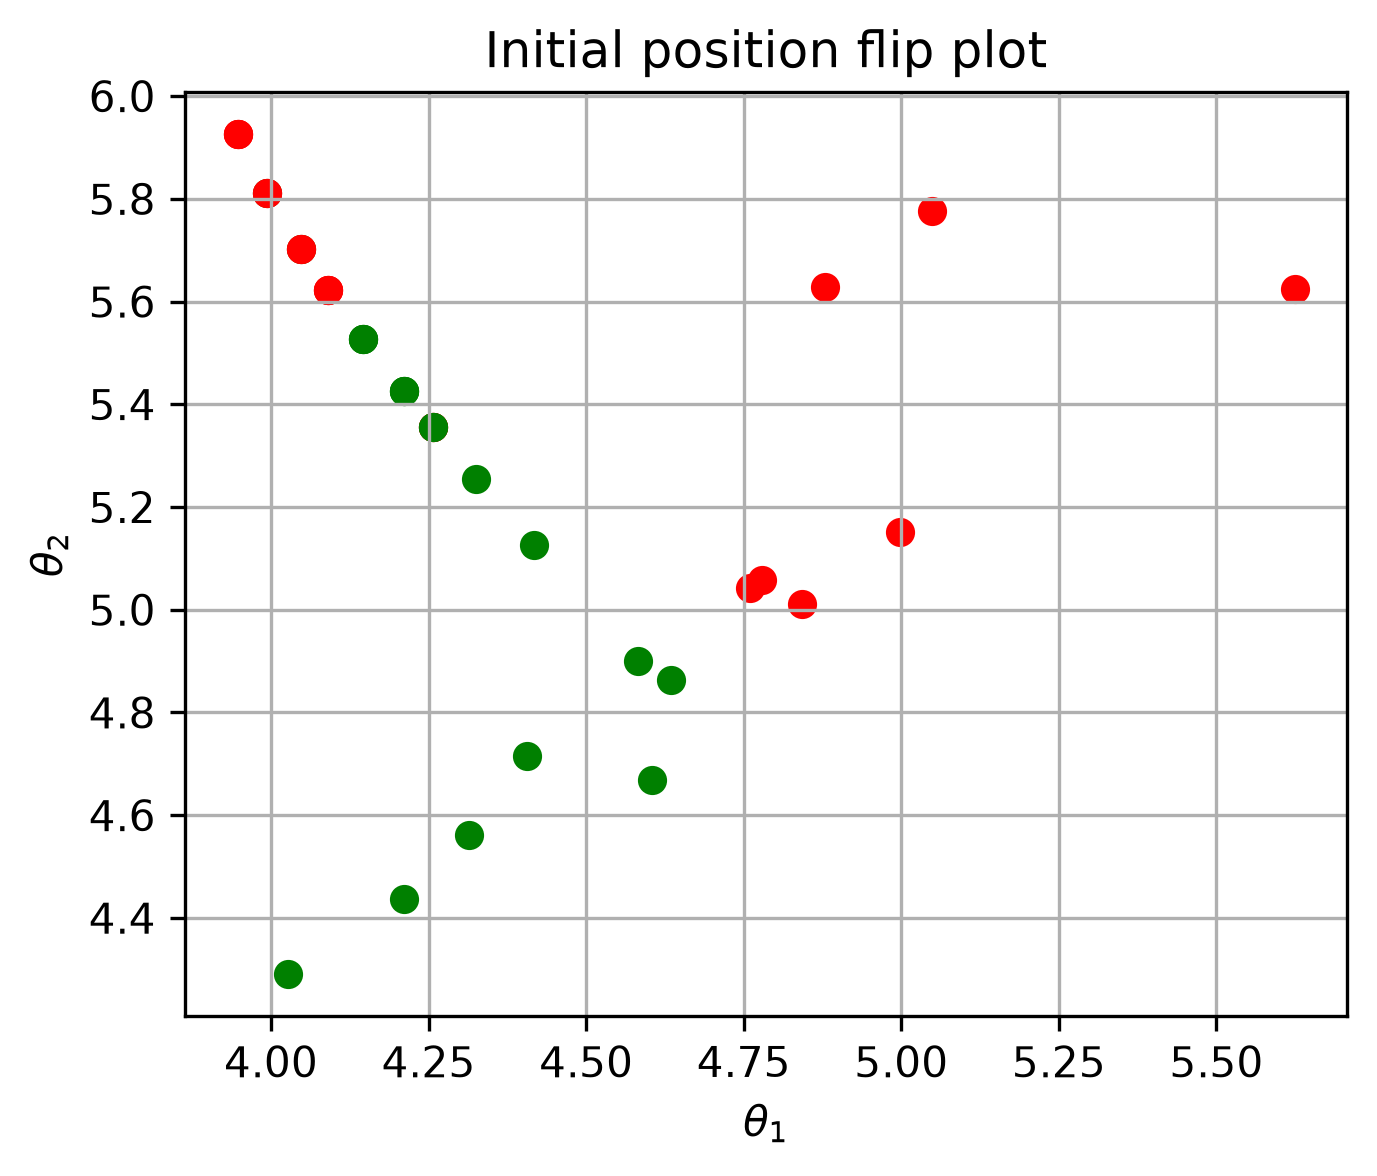

In [49]:

fig, ax = plt.subplots(figsize=(5, 4), dpi=300)
for i,_ in enumerate(X):
    if flip[i] == 0:
        color = "red"
    else:
        color = "green"
    ax.scatter(theta_1[i] , theta_2[i], color=color)

ax.set_xlabel(r"$\theta_1$")
ax.set_ylabel(r"$\theta_2$")
ax.set_title("Initial position flip plot")
ax.grid()
#plt.legend()
#plt.tight_layout()
#save_dir.mkdir(exist_ok=True)
#fig.savefig(save_dir / f"{res['group']}_{res['name']}.pdf")
#plt.close(fig)
plt.show()